In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Dials
g_rAmbient = 1000. #1kHz
g_rAmbS = 0.
g_tResAcoustic = 10.e-6
g_TimeBubble = 60. #average time between bubbles. Maybe push to 2 minutes because 1minute is absolute limit. this ignores other bubble causing bkgs.
# Worse case we say this measurement is to be done in the snolab chamber which will have about 1 per hour

# From Noah's simulation work
g_pNR = 1.e-6
g_pER = 0.30
g_f = 0.01
g_PDE = 0.01
g_Bt = 1./3.
g_avgPE = 2.

# relevant rates
g_rSource = 1./g_TimeBubble/g_pNR #this is gamma rate in the chamber's sensitive volume. which is close enough to the scintillation sensitive volume

# superfluous
RNR = g_rSource * g_pNR # by definition same as 1/TimeBubble. 
RER = g_rSource * g_pER

print(g_rSource*g_pER)

5000.0


In [3]:
## quick Parameter organization ##
"""
rs - gamma source rate
ramb - ambient 1PE rate
rambS - ambient large pulse rate. approximated as zero for now

pnr - probability of Nuclear recoil above threshold
per - probability of measurable electron recoil
f - fraction of ERs causing 1PE. small

pde - SBC's Photo detection ability
avgpe - Average of E_NR * LY, this is the variable of interest

tac - acoustic event resolution
bt - bubble time or duty cycle. 'fraction of time chamber is NR sensitive'
"""

paramsConservative = {"rs": g_rSource, "ramb":g_rAmbient, "rambS": g_rAmbS, \
                      "pnr":g_pNR, "per": g_pER, "f": g_f, \
                      "pde":g_PDE, "avgpe":g_avgPE, \
                      "tac":g_tResAcoustic, "bt": g_Bt}

paramsBadtiming = paramsConservative.copy()
paramsBadtiming["tac"]*=10

paramsMediumLY = paramsConservative.copy()
paramsMediumLY['avgpe']*=0.5

paramsWeakGammas = paramsConservative.copy()
paramsWeakGammas["f"] = 0.99

paramsDead = paramsConservative.copy()
paramsDead["avgpe"] = 0.

In [4]:
def Rother1pe(**p):
    return p['ramb'] + p['rs']*p['per']*p['f']
    # return Ramb + Rgamma*Per*f

def Rbig(**p):
    return p['rambS'] + p['rs']*p['per']*(1-p['f'])
    # return RambStar + Rgamma*Per*(1-f)

def GetPoissonError(deltaT, rate):
    return np.sqrt(rate/deltaT)

# this is a poisson with 1 event
def P_1PE_in_acoustic(**p):
    tac = p["tac"]
    rate = Rother1pe(**p)
    lam = tac * rate
    return lam * np.exp(-lam)

# poisson 0, using Rbig rate
def P_noBig(**p):
    tac = p["tac"]
    R = Rbig(**p)
    return np.exp(-R*tac)

print(f"P_1pe_in_acoustic: for ambient rate {g_rAmbient:0.1f} Hz,{g_tResAcoustic/1e-6 : .1f} us resolution ={100*P_1PE_in_acoustic(**paramsConservative) : 0.2f}%")
print(f"P_1pe_in_acoustic: for ambient rate {g_rAmbient:0.1f} Hz,{(g_tResAcoustic*10)/1e-6 : .1f} us resolution = {100*P_1PE_in_acoustic(**paramsBadtiming) : 0.2f}%")

print(f"\nP_noBig: for ambient rate {g_rAmbient:0.1f} Hz,{g_tResAcoustic/1e-6 : .1f} us resolution ={100*P_noBig(**paramsConservative) : 0.2f}%")
print(f"P_noBig: for ambient rate {g_rAmbient:0.1f} Hz,{(g_tResAcoustic*10)/1e-6 : .1f} us resolution = {100*P_noBig(**paramsBadtiming) : 0.2f}%")

P_1pe_in_acoustic: for ambient rate 1000.0 Hz, 10.0 us resolution = 1.04%
P_1pe_in_acoustic: for ambient rate 1000.0 Hz, 100.0 us resolution =  9.45%

P_noBig: for ambient rate 1000.0 Hz, 10.0 us resolution = 95.17%
P_noBig: for ambient rate 1000.0 Hz, 100.0 us resolution =  60.96%


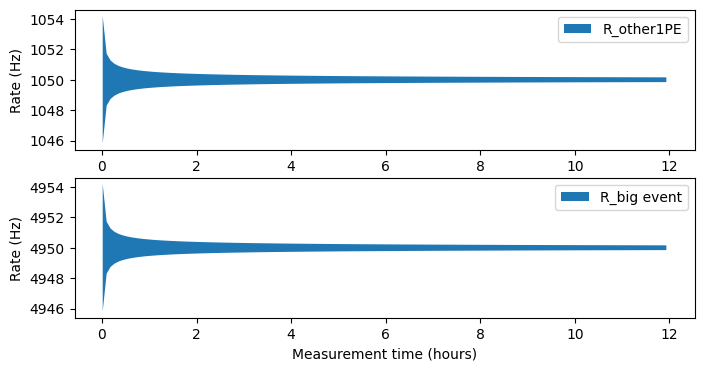

Takeaway: due to high rates, uncertainty on polluting or 'leakage' event rate is
negligible after any considerable data taking


In [5]:
## Checking how quickly error reduces to negligible from fluctuations

Ndays = 0.5
hour = 60*60
times = np.arange(60, Ndays*24*hour, hour/12) #Ndays in units of seconds, separated by hours

# R_exp_other1pe(times, rAmbient, rSource, pER, f)
rOther = Rother1pe(**paramsConservative)
rOtherError = GetPoissonError(times, rOther)

rBig = Rbig(**paramsConservative)
rBigError = GetPoissonError(times, rOther)

fig, ax = plt.subplots(2, 1, figsize = (8, 4))

ax[0].fill_between(times/hour, y1 = rOther + rOtherError, y2 = rOther - rOtherError, label = "R_other1PE")
ax[0].set_ylabel("Rate (Hz)")
ax[0].set_xlabel("Measurement time (hours)")
ax[0].legend()

ax[1].fill_between(times/hour, y1 = rBig + rBigError, y2 = rBig - rBigError, label = "R_big event")
ax[1].set_ylabel("Rate (Hz)")
ax[1].set_xlabel("Measurement time (hours)")
ax[1].legend()
plt.show()

print("Takeaway: due to high rates, uncertainty on polluting or 'leakage' event rate is\nnegligible \
after any considerable data taking")

$$ R_{big} = R^*_{amb} + R_\gamma P_{ER} (1-f) $$  
$$ R_{other1PE} = R_{amb} + R_\gamma P_{ER} f $$  
$$P_{noBig} = Poisson(k=0|\lambda = R_{big}t_{ac}) = e^{-t_{ac}R_{big}} $$  
$$P_{other1PE} = Poisson(k=1|\lambda = R_{other}t_{ac}) = R_{other}t_{ac} e^{-R_{other}t_{ac}} $$  
$$P_{NR1PE} = Binomial(M=1, N=2 |p = PDE) = <LY \cdot E_NR> PDE (1-PDE) $$  
$$ \frac{N_{1PE}}{\Delta t} = B_T R_\gamma P_{NR} (1 - P_{ER}) P_{noBig}\Big[P_{other1PE} + P_{NR1PE} - P_{other1PE}P_{NR1PE}\Big] $$  

$$ N_{LY} = N_{1PE} - N_{1PE}(LY=0) $$  

$$ \sigma_{N_{LY}} \approx \sqrt{N_{1PE} + N_{1PE}(LY=0)} $$


In [6]:
def N1pePreFac(**p):
    rs = p["rs"]
    pNR = p["pnr"]
    pER = p["per"]
    bt = p["bt"]
    return bt*rs*pNR*(1 - pER) * P_noBig(**p)

## binomial with avgPE trials, pde chance of success
def P_NR1PE(**p):
    pde = p["pde"]
    avgPE = p["avgpe"]
    return avgPE*pde*(1-pde)

def N_1pe_all(deltaT, **p):  
    prefac = N1pePreFac(**p)
    pOther = P_1PE_in_acoustic(**p)
    pNRLY = P_NR1PE(**p)
    return deltaT * prefac*(pOther + pNRLY - pOther*pNRLY)

def N_1pe_dead(deltaT, **p):  
    prefac = N1pePreFac(**p)
    pOther = P_1PE_in_acoustic(**p)
    return deltaT * prefac*(pOther)

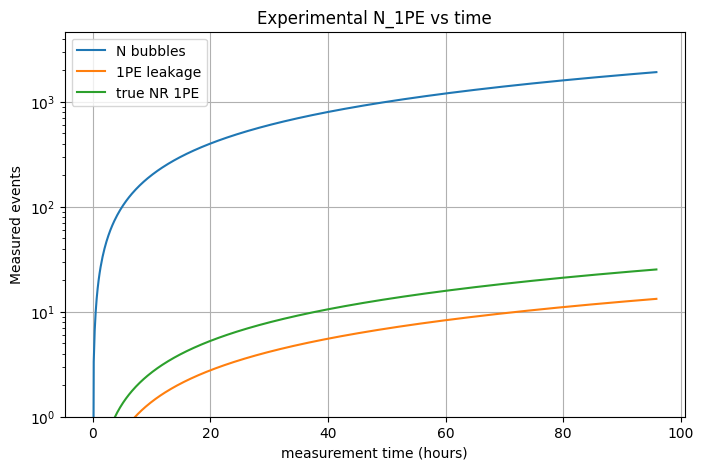

In [7]:
Ndays = 4
hour = 60*60
times = np.arange(1, Ndays*24*hour, hour/6) #Ndays in units of seconds, separated by hours

fig = plt.subplots(1, 1, figsize=(8, 5))
nBubbles = times * g_Bt/g_TimeBubble
plt.plot(times/hour, nBubbles, label = "N bubbles")
plt.plot(times/hour, nBubbles * (1-g_pER) * P_noBig(**paramsConservative) * P_1PE_in_acoustic(**paramsConservative), label = "1PE leakage")
plt.plot(times/hour, nBubbles * (1-g_pER) * P_noBig(**paramsConservative) * P_NR1PE(**paramsConservative), label = "true NR 1PE")

plt.ylabel("Measured events")
plt.xlabel("measurement time (hours)")
plt.title("Experimental N_1PE vs time")
plt.legend()
plt.grid()
plt.yscale("log")
plt.ylim(bottom = 1)
plt.show()

In [8]:
def output(times, **p):
    Nly = N_1pe_all(times, **p) - N_1pe_dead(times, **p)
    sigN = np.sqrt(N_1pe_all(times, **p) + N_1pe_dead(times, **p))
    return Nly, sigN

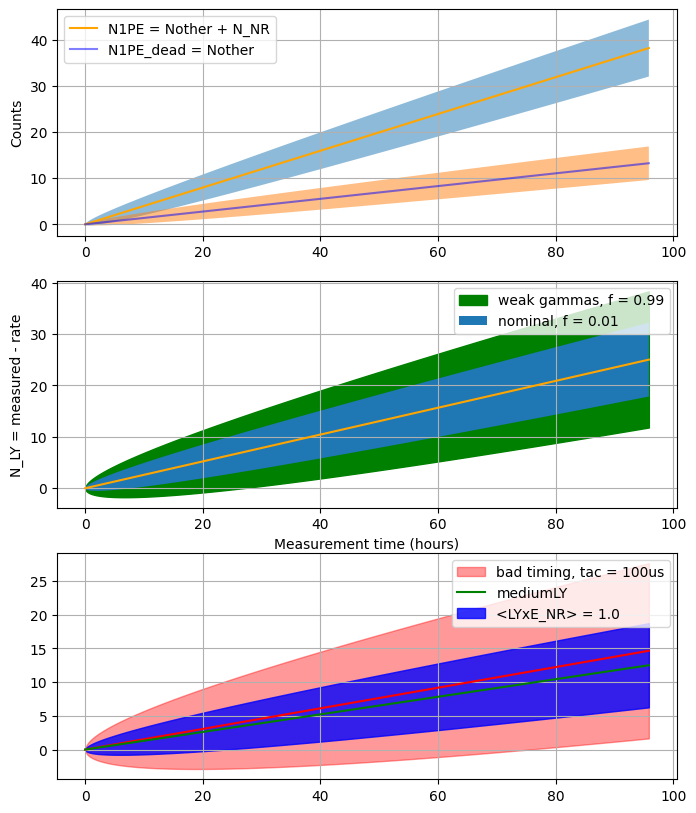

In [9]:
pUse = paramsBadtiming
pUse = paramsConservative

fig, ax = plt.subplots(3, 1, figsize = (8, 10))
ax2 = ax[1]
ax3 = ax[2]
ax = ax[0]

Nall = N_1pe_all(times, **pUse)
sigNall = np.sqrt(Nall)

Nalldead = N_1pe_dead(times, **pUse)
sigNalldead = np.sqrt(Nalldead)

ax.plot(times/hour, Nall, linestyle = "-", color = "orange", label = "N1PE = Nother + N_NR")
ax.fill_between(times/hour, Nall + sigNall, Nall - sigNall, alpha = 0.5)
ax.plot(times/hour, Nalldead, linestyle = "-", color = "blue", alpha = 0.5, label = "N1PE_dead = Nother")
ax.fill_between(times/hour, Nalldead + sigNalldead, Nalldead - sigNalldead, alpha = 0.5)

ax.set_ylabel("Counts")
ax.legend()
ax.grid()

# N1peDead = N1pe = GetN1pe(times, **paramsDead)
out1 = output(times, **paramsConservative)
out2 = output(times, **paramsWeakGammas)
ax2.plot(times/hour, out1[0], color = 'orange')

ax2.fill_between(times/hour, out2[0]-out2[1], out2[0]+out2[1], color = 'green', label = "weak gammas, f = 0.99")
ax2.fill_between(times/hour, out1[0]-out1[1], out1[0]+out1[1], label = "nominal, f = 0.01")


ax2.set_ylabel("N_LY = measured - rate")
ax2.set_xlabel("Measurement time (hours)")
ax2.legend()
ax2.grid()

out2_1 = output(times, **paramsBadtiming)
ax3.plot(times/hour, out2_1[0], color = "red")
ax3.fill_between(times/hour, out2_1[0]-out2_1[1], out2_1[0]+out2_1[1], color = 'red', alpha = 0.4, label = "bad timing, tac = 100us")

out3 = output(times, **paramsMediumLY)
ax3.plot(times/hour, out3[0], color = 'green', label = "mediumLY")
ax3.fill_between(times/hour, out3[0]+out3[1], out3[0]-out3[1], color = 'blue', alpha = 0.8, label = "<LYxE_NR> = 1.0")
ax3.grid()
ax3.legend()

plt.show()

In [10]:
def getPrecision(deltaT, **pars):
    total = N_1pe_all(deltaT, **pars)
    dead = N_1pe_dead(deltaT, **pars)
    nly = total - dead
    return np.sqrt(total + dead)/nly

# getPrecision(10., **paramsConservative)
type(paramsConservative)
getPrecision(48*hour, **paramsWeakGammas)

0.7466999883809728

In [23]:
## Run for two days
t_twoDays = 48.*hour

fValues = np.arange(0.01, 0.5, 0.1)
tacValues = np.arange(10.e-6, 100.e-6, 10.e-6)
z = np.ndarray(shape = (len(tacValues), len(fValues)), dtype=float)
for ix, f in np.ndenumerate(fValues):
    for iy, tac in np.ndenumerate(tacValues):
        p = paramsConservative.copy()
        p['tac'] = tac
        p['f'] = f
        precision = getPrecision(t_twoDays, **p)
        z[iy[0]][ix[0]] = precision

fvals, tvals = np.meshgrid(fValues, tacValues)
print(fvals.shape)


(9, 5)


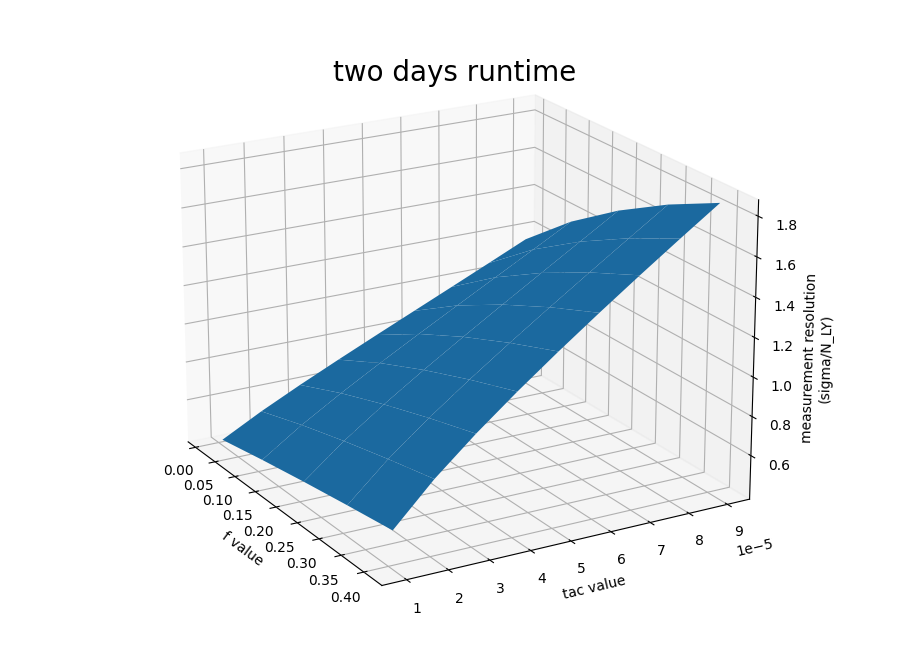

In [220]:
# plt.rcParams["figure.figsize"] = [7.50, 3.50]
# plt.rcParams['savefig.facecolor'] = "0.8"


fig, (d1, ax, d2) = plt.subplots(1, 3, subplot_kw={"projection": "3d"}, width_ratios=(1, 10,1), figsize = (10,10))
d1.axis('off')
d2.axis('off')
# fig.bbox_inches = 0.1
# fig.set_facecolor('red')
# ax.set_facecolor('green')

# fig.subplots_adjust(hspace = .0)
ax.plot_surface(fvals, tvals, z, label = "two days runtime")
# ax.legend()

ax.set_title("two days runtime", y = 1.2, fontsize = 20, pad = -100)
ax.set_xlabel("f value")
ax.set_ylabel("tac value")
ax.set_zlabel("measurement resolution\n(sigma/N_LY)", labelpad = 5)

ax.view_init(20, 330)

fig.tight_layout(pad = 4)